<!-- d2l:prose id=autorec-md-1 fw=all -->

# AutoRec: Rating Prediction with Autoencoders

Matrix factorization assigns each user and item a vector and scores their
interaction with a bilinear function. AutoRec replaces that score with a
nonlinear reconstruction map [@Sedhain.Menon.Sanner.ea.2015]. Its input is
a partially observed row or column of the rating matrix, and its output predicts
ratings for the same user or item. The observation mask, rather than the filler
value used for missing entries, determines which reconstruction errors enter the
loss.

Like an ordinary autoencoder, AutoRec contains an encoder, a hidden
representation, and a decoder. Its distinctive feature is the data it
reconstructs: a sparse vector of ratings rather than a fully observed example.
The hidden representation and decoder are learned jointly from errors on the
observed output coordinates; predictions at unobserved coordinates supply the
recommendations.

An item-based AutoRec reconstructs one item column across users. A user-based
variant applies the same construction to user rows. We develop the item-based
version.


## Model

Let $\mathbf R\in\mathbb R^{m\times n}$ contain ratings from $m$ users for
$n$ items, and let $M_{ui}=1$ when $R_{ui}$ is observed and $0$ otherwise.
For item $i$, the network input is the filled vector
$\mathbf x_i=\mathbf M_{*i}\odot\mathbf R_{*i}\in\mathbb R^m$. Zero is only a
computational filler; $\mathbf M$ determines which entries are missing. With a
hidden width $h$, item-based AutoRec computes

$$
h_\theta(\mathbf x_i)
=f\!\left(\mathbf Wg(\mathbf V\mathbf x_i+\boldsymbol\mu)+\mathbf b\right),
$$

where $\mathbf V\in\mathbb R^{h\times m}$,
$\boldsymbol\mu\in\mathbb R^h$, $\mathbf W\in\mathbb R^{m\times h}$, and
$\mathbf b\in\mathbb R^m$. The output contains one reconstructed rating per
user.

The observation mask is applied to the output error:

$$
\underset{\theta}{\operatorname{minimize}}\quad
\sum_{i=1}^n\sum_{u=1}^m
M_{ui}\big(R_{ui}-h_\theta(\mathbf x_i)_u\big)^2
+\lambda\big(\|\mathbf W\|_F^2+\|\mathbf V\|_F^2\big).
$$

Masking removes loss terms for unobserved *outputs*. It does not restrict an
update to a subset of parameters: every encoder or decoder parameter that
influences an observed reconstruction may receive a gradient.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

<!-- d2l:prose id=autorec-md-2 fw=all -->

## Implementing the Model

The implementation uses a sigmoid encoder, a linear decoder, and dropout on the
hidden representation. During training, multiplying the predictions by the
binary observation mask makes the squared loss equivalent to the elementwise
objective above. During evaluation, the unmasked output is needed because its
unobserved coordinates are the predictions of interest. This code assumes all
recorded ratings are positive, so `sign(input)` is the binary mask.

In [2]:
class AutoRec(nn.Module):
    def __init__(self, num_hidden, num_users, dropout=0.05):
        super().__init__()
        self.encoder = nn.Linear(num_users, num_hidden)
        self.decoder = nn.Linear(num_hidden, num_users)
        self.dropout = nn.Dropout(dropout)

    def forward(self, input):
        hidden = self.dropout(torch.sigmoid(self.encoder(input)))
        pred = self.decoder(hidden)
        if self.training:  # Mask unobserved output errors
            return pred * torch.sign(input)
        else:
            return pred

<!-- d2l:prose id=autorec-md-3 fw=all -->

## Reimplementing the Evaluator

Since the input and output have been changed, we need to reimplement the evaluation function, while we still use RMSE as the accuracy measure.

In [3]:
def evaluator(network, inter_matrix, test_data, devices):
    network.eval()
    scores = []
    with torch.no_grad():
        for values in inter_matrix:
            values = values.to(devices[0])
            scores.append(network(values).cpu().numpy())
    recons = np.concatenate(scores, axis=0)
    # Calculate the test RMSE
    rmse = np.sqrt(
        np.sum(np.square(test_data - np.sign(test_data) * recons))
        / np.sum(np.sign(test_data)))
    return float(rmse)

<!-- d2l:prose id=autorec-md-4 fw=all -->

## Training and Evaluating the Model

We train AutoRec on the MovieLens split defined earlier and report RMSE over held-out observed ratings. In this run its RMSE can be compared with the matrix-factorization run only as a local result: the architectures, tuning budgets, and random variation have not been controlled well enough to attribute the difference to nonlinearity alone.

train loss 39.739, test RMSE 0.906


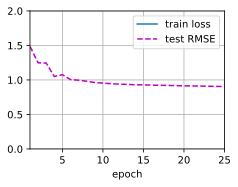

In [4]:
devices = d2l.try_all_gpus()
# Load the MovieLens 100K dataset
df, num_users, num_items = d2l.read_data_ml100k()
train_data, test_data = d2l.split_data_ml100k(df, num_users, num_items)
_, _, _, train_inter_mat = d2l.load_data_ml100k(train_data, num_users,
                                                num_items)
_, _, _, test_inter_mat = d2l.load_data_ml100k(test_data, num_users,
                                               num_items)
train_inter_mat_t = torch.tensor(train_inter_mat, dtype=torch.float32)
test_inter_mat_np = np.array(test_inter_mat)
train_iter = torch.utils.data.DataLoader(train_inter_mat_t, shuffle=True,
                                         drop_last=True, batch_size=256,
                                         num_workers=d2l.get_dataloader_workers())
test_iter = torch.utils.data.DataLoader(train_inter_mat_t, shuffle=False,
                                        batch_size=1024,
                                        num_workers=d2l.get_dataloader_workers())
# Model initialization, training, and evaluation
net = AutoRec(500, num_users)
nn.init.normal_(net.encoder.weight, std=0.01)
nn.init.normal_(net.decoder.weight, std=0.01)
net = net.to(devices[0])
lr, num_epochs, wd = 0.002, 25, 1e-5
loss = nn.MSELoss(reduction='sum')
optimizer = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=wd)
timer = d2l.Timer()
animator = d2l.Animator(xlabel='epoch', xlim=[1, num_epochs], ylim=[0, 2],
                        legend=['train loss', 'test RMSE'])
for epoch in range(num_epochs):
    net.train()
    total_loss, n = 0., 0
    for i, values in enumerate(train_iter):
        timer.start()
        values = values.to(devices[0])
        optimizer.zero_grad()
        preds = net(values)
        # The model already zeros out predictions where the input rating is
        # 0 (unobserved). Comparing against `values` directly therefore
        # gives a loss that only penalizes observed entries, matching the
        # masked-loss formulation used in the MXNet branch.
        l = loss(preds, values)
        l.backward()
        optimizer.step()
        total_loss += l.item()
        n += values.shape[0]
        timer.stop()
    test_rmse = evaluator(net, test_iter, test_inter_mat_np, devices)
    train_l = total_loss / n
    animator.add(epoch + 1, (train_l, test_rmse))
print(f'train loss {total_loss / n:.3f}, test RMSE {test_rmse:.3f}')

<!-- d2l:prose id=autorec-md-5 fw=all -->

## Summary

* AutoRec learns a nonlinear map from a partially observed rating vector to its
  reconstruction; an observation mask restricts the training error to known
  ratings.
* On the MovieLens split and hyperparameters used here, AutoRec obtains a lower
  test RMSE than the matrix-factorization run. This local comparison is not a
  general ranking of the two model classes.


## Exercises

1. Show that the item-based AutoRec of this section predicts the same vector
   $f(\mathbf W g(\boldsymbol\mu)+\mathbf b)$ for every item without training
   ratings, so each user gives all such items the same score. Compare with
   what `MF` predicts for an item that never occurs in training. Which input
   would a model need to give new items distinct scores?
1. The evaluator reconstructs each item from its *training* column and
   compares the reconstruction with the test ratings. Predict what happens to
   the test RMSE if the network is fed the columns of `test_inter_mat`
   instead, then compute it with the trained `net`. Why does that number not
   measure prediction?
1. AutoRec is trained on `split_data_ml100k` with its default
   `split_mode='random'`, while the matrix-factorization experiment uses
   `split_and_load_ml100k`, whose default is `'seq-aware'`. Train `MF` on the
   random split used here and AutoRec on the `seq-aware` split, and tabulate
   the four test RMSEs. Does the comparison in the summary hold on a shared
   split?
1. Train AutoRec with hidden width $h\in\{50, 200, 500, 1000\}$ and dropout
   rates $0.05$ and $0.5$, and tabulate the test RMSE. Compare the number of
   parameters at each width with the number of training ratings. Which
   setting overfits, and does the larger dropout rate change the best width?
1. Implement user-based AutoRec by transposing the rating matrix, so that each
   input is a user's row of length $n$. Compare the number of parameters, the
   number of input vectors per epoch, and the mean number of observed entries
   per input vector with those of the item-based model, and report its test
   RMSE on the same split.

<!-- d2l:prose id=autorec-md-6 fw=pytorch -->

[Discussions](https://d2l.discourse.group/t/401)